In [15]:
from qiskit import __version__

print(__version__)

2.5.2


Deutsch's Algorithm

In [16]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator


In [17]:
def deutsch_function(case: int):
    if case not in [1, 2, 3, 4]:
        raise ValueError("Invalid case number. Must be 1, 2, 3, or 4.")
    f = QuantumCircuit(2)
    if case in [2, 3]:
        f.cx(0, 1)
    if case in [3, 4]:
        f.x(1)
        return f

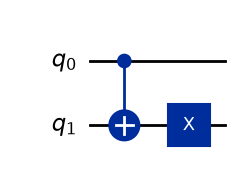

In [18]:
display(deutsch_function(3).draw(output="mpl"))

In [19]:
def compile_circuit(function: QuantumCircuit):
    n = function.num_qubits - 1
    qc = QuantumCircuit(n + 1, n)
    qc.x(n)
    qc.h(range(n+1))

    qc.barrier()
    qc.compose(function, inplace=True)
    qc.barrier()
    
    qc.h(range(n))
    qc.measure(range(n), range(n))

    return qc

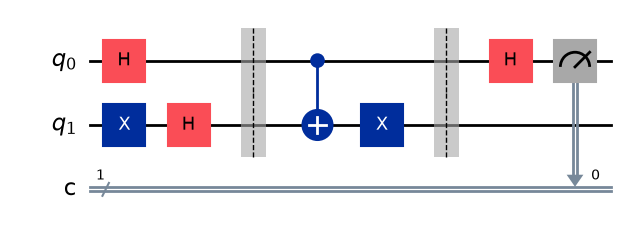

In [20]:
display(compile_circuit(deutsch_function(3)).draw(output="mpl"))

In [21]:
def deutsch_algorithm(function: QuantumCircuit):
    qc = compile_circuit(function)
    results = AerSimulator().run(qc, shots=1, memory=True).result()
    measurements = results.get_memory()
    if measurements[0] == '0':
        return "constant"
    else:
        return "balanced"

In [22]:
f = deutsch_function(3)
display(deutsch_algorithm(f))

'balanced'

Deutsch-Josza Algorithm

In [23]:
import numpy as np

In [48]:
def dj_query(num_qubits):
    qc = QuantumCircuit(num_qubits+1)
    if np.random.randint(0, 2):
        qc.x(num_qubits)
    if np.random.randint(0, 2):
        return qc
    on_states = np.random.choice(range(2**num_qubits),2**num_qubits//2, replace=False)
    def add_cx(qc, bit_string):
        for qubit, bit in enumerate(reversed(bit_string)):
            if bit == '1':
                qc.x(qubit)
        return qc
    for state in on_states:
        qc.barrier()
        qc = add_cx(qc, f"{state:0b}")
        qc.mcx(list(range(num_qubits)), num_qubits)
        qc = add_cx(qc, f"{state:0b}")

    qc.barrier()

    return qc


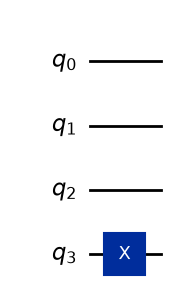

In [59]:
display(dj_query(3).draw(output="mpl"))

In [60]:
def compile_circuit(function: QuantumCircuit):
    n = function.num_qubits - 1
    qc = QuantumCircuit(n + 1, n)
    qc.x(n)
    qc.h(range(n+1))

    qc.barrier()
    qc.compose(function, inplace=True)
    qc.barrier()
    
    qc.h(range(n))
    qc.measure(range(n), range(n))

    return qc

In [61]:
def dj_algorithm(function: QuantumCircuit):
    qc = compile_circuit(function)
    result = AerSimulator().run(qc, shots=1, memory=True).result()
    measurements = result.get_memory()
    if "1" in measurements[0]:
        return "balanced"
    return "constant"

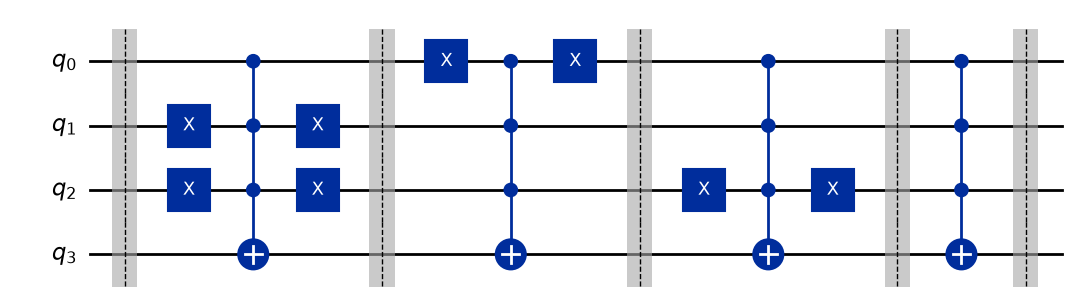

'balanced'

In [87]:
f = dj_query(3)
display(f.draw("mpl"))
display(dj_algorithm(f))

Bernstein-Vazirani

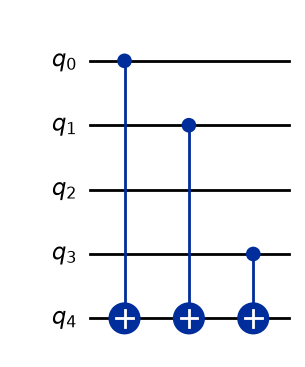

In [88]:
def bv_query(s):
    qc = QuantumCircuit(len(s)+1)
    for index, bit in enumerate(reversed(s)):
        if bit == '1':
            qc.cx(index, len(s))
    return qc

display(bv_query("1011").draw(output="mpl"))

In [89]:
def bv_algorithm(function: QuantumCircuit):
    qc = compile_circuit(function)
    result = AerSimulator().run(qc, shots=1, memory=True).result()
    return result.get_memory()[0]
display(bv_algorithm(bv_query("1011")))

'1011'